In [1]:
import sys
from pathlib import Path

import blosc2
import matplotlib.pyplot as plt
import numpy as np
import tifffile
from skimage.color import label2rgb

sys.path.insert(0, str(Path.cwd()))
raw = Path("data/raw")
pre = Path.home() / "nnunet/preprocessed/Dataset501_TEM/nnUNetPlans_2d"
case = "sample_0002"


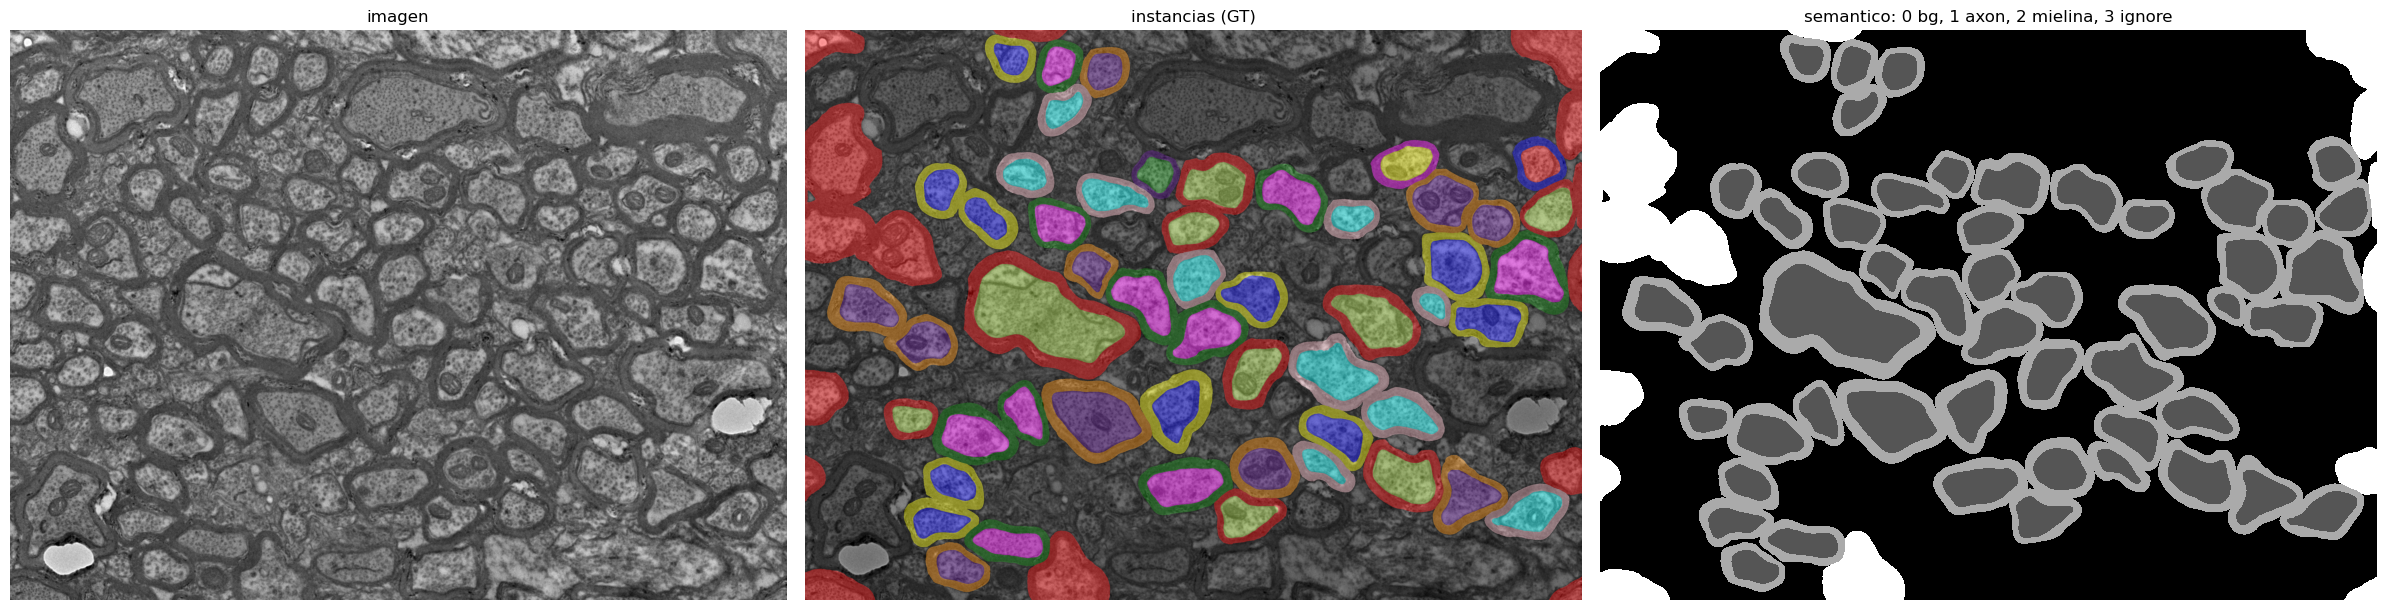

In [2]:
img = tifffile.imread(raw / "train_samples" / f"{case}.tif")
gt = tifffile.imread(raw / "train_instance_labels" / f"{case}.tif")
sem = np.where(gt >= 2, 1 + gt % 2, 0)
sem[gt == 1] = 3

fig, ax = plt.subplots(1, 3, figsize=(24, 6), sharex=True, sharey=True)
ax[0].imshow(img, cmap="gray")
ax[1].imshow(label2rgb(gt, img, alpha=0.4, bg_label=0))
ax[2].imshow(sem, cmap="gray", interpolation="nearest")
for a, t in zip(ax, ["imagen", "instancias (GT)", "semantico: 0 bg, 1 axon, 2 mielina, 3 ignore"]):
    a.set_title(t)
    a.axis("off")
plt.tight_layout()


(1, 1, 3008, 4096) float32 (1, 1, 3008, 4096) [-1  0  1  2  3]


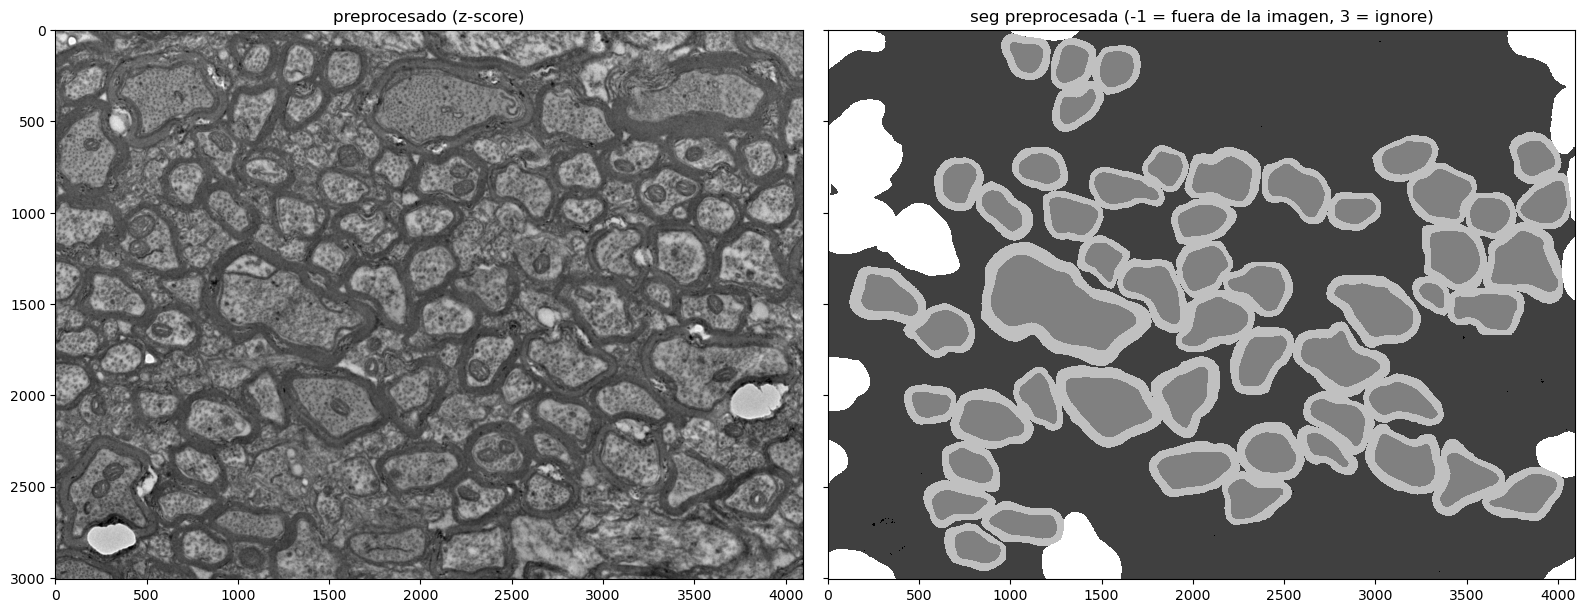

In [3]:
data = blosc2.open(str(pre / f"{case}.b2nd"), mode="r")[:]
seg = blosc2.open(str(pre / f"{case}_seg.b2nd"), mode="r")[:]
print(data.shape, data.dtype, seg.shape, np.unique(seg))

fig, ax = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
ax[0].imshow(data[0, 0], cmap="gray")
ax[0].set_title("preprocesado (z-score)")
ax[1].imshow(seg[0, 0], cmap="gray", interpolation="nearest")
ax[1].set_title("seg preprocesada (-1 = fuera de la imagen, 3 = ignore)")
plt.tight_layout()


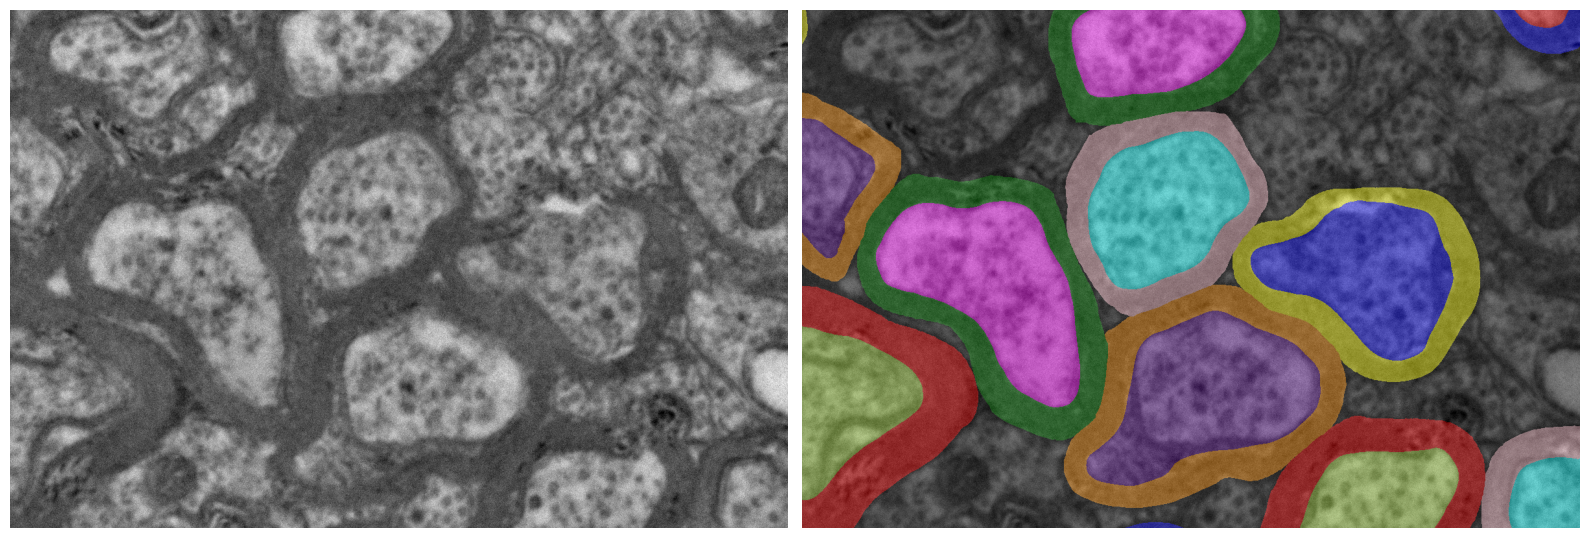

In [4]:
ys, xs = slice(1000, 1800), slice(1500, 2700)
fig, ax = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)
ax[0].imshow(img[ys, xs], cmap="gray")
ax[1].imshow(label2rgb(gt[ys, xs], img[ys, xs], alpha=0.4, bg_label=0))
for a in ax:
    a.axis("off")
plt.tight_layout()
